## 04 Refining Clusters and Annotations

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sc.settings.set_figure_params(dpi=120, facecolor='white', frameon=False)

file_path = "/mnt/..processed/adata_integrated_cleaned.h5ad"
adata = sc.read_h5ad(file_path)

# 确保索引唯一
adata.obs_names_make_unique()
print(f"Loaded: {adata.n_obs} cells")

Loaded: 61350 cells


/home/bio02/miniconda3/envs/sc2/lib/python3.11/site-packages/anndata/_core/anndata.py:1774: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


/tmp/ipykernel_568/1059700314.py:6: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=res, key_added=f'leiden_res_{res}')


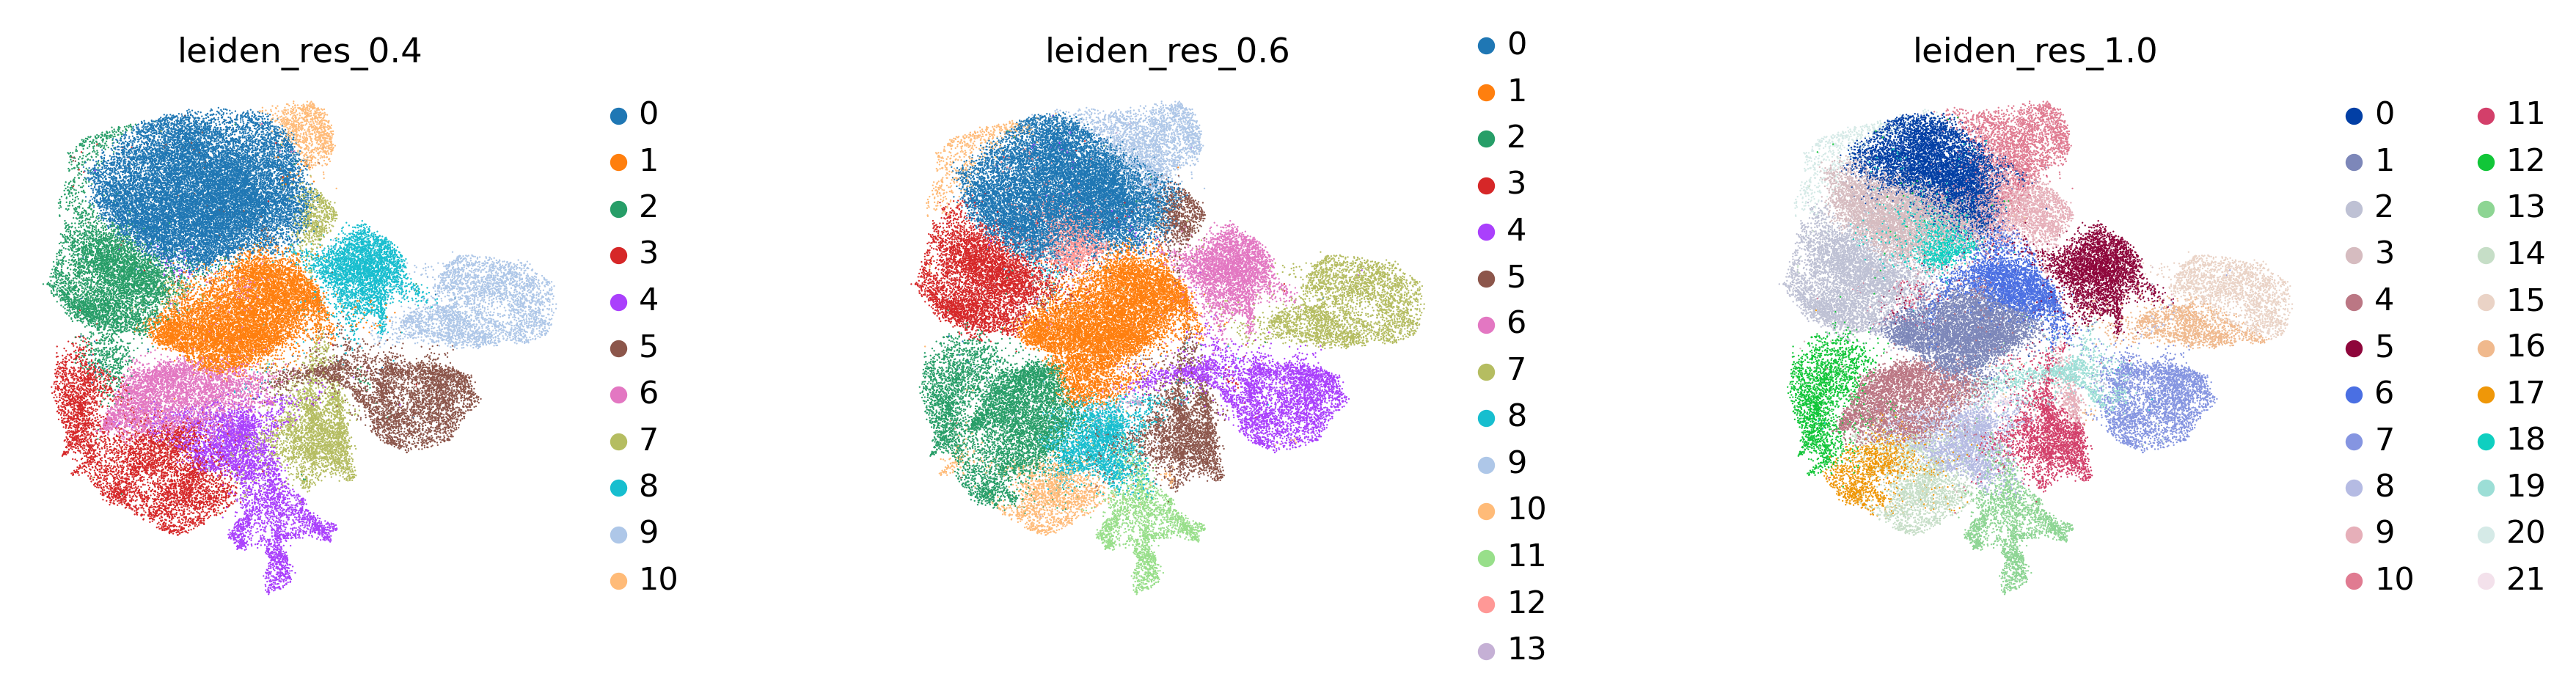

In [ ]:
# sc.pp.neighbors(adata, use_rep='X_scVI')
for res in [0.4, 0.6, 1.0]:
    sc.tl.leiden(adata, resolution=res, key_added=f'leiden_res_{res}')

sc.pl.umap(adata, color=['leiden_res_0.4', 'leiden_res_0.6', 'leiden_res_1.0'], wspace=0.4)

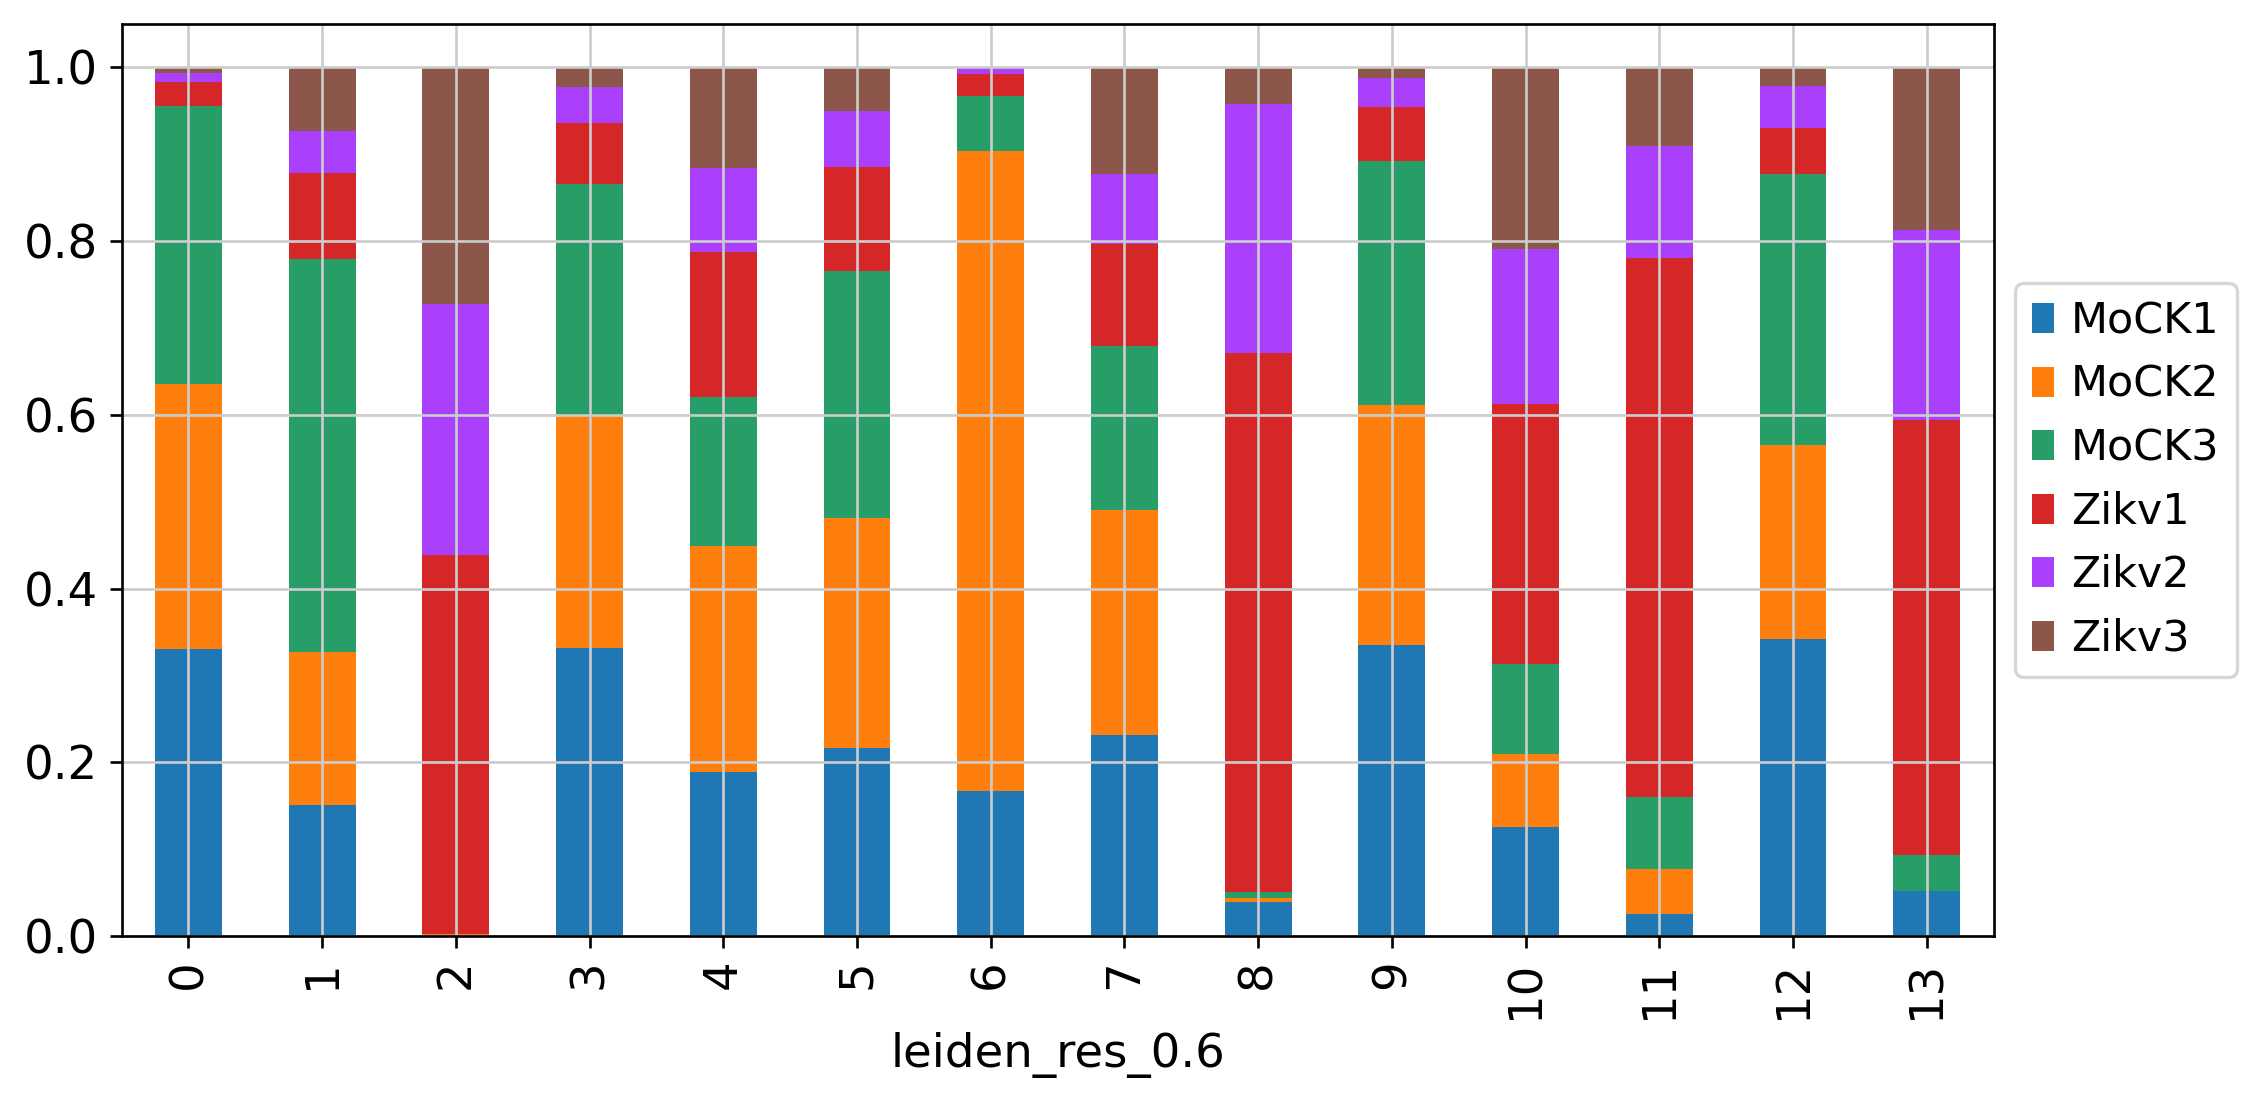

In [ ]:
tmp = pd.crosstab(adata.obs['leiden_res_0.6'], adata.obs['Sample'], normalize='index')
tmp.plot.bar(stacked=True, figsize=(10, 5)).legend(loc='center left', bbox_to_anchor=(1, 0.5))

Top 10 markers for all clusters (0-13):
             0        1        2          3       4             5       6  \
0        DACH1    GAPDH   bingdu      TOP2A  TFAP2B           FTL   RPS4X   
1       COL4A6     RPS8   SNRPD2      CENPF    PLP1          EIF1    RPS7   
2       COL4A5  HNRNPA1    DGUOK     DIAPH3    PAX3         ZFAS1   RPS3A   
3  RP11-32K4.1    H3F3A    SRP14      MKI67    LMO4         ALDOA   RPL30   
4         GPC3    RPLP1   SNRPD1       SMC4  CCSER1         DDIT3   RPS23   
5        SLIT2     RPS6    ISG15     NUSAP1    NRP2        SQSTM1  RPS27A   
6        GPM6A    RPS24  TRMT112   HIST1H4C   ITGA4  EPB41L4A-AS1   RPL11   
7       CTNNA2     RPL7    SNRPB   MIS18BP1   ERBB3          VAT1   RPS12   
8        WNT5B    RPL41    SERF2  ARHGAP11B   ROBO1          ENO2   RPL10   
9       ADGRL3   EEF1A1    RPL38       ASPM  SEMA3C          NEU1   RPL24   

         7       8        9       10         11        12      13  
0   TMSB4X  bingdu  ARL6IP1   bingdu      KR

/home/bio02/miniconda3/envs/sc2/lib/python3.11/site-packages/scanpy/tools/_utils.py:40: UserWarning: You’re trying to run this on 21250 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  warnings.warn(


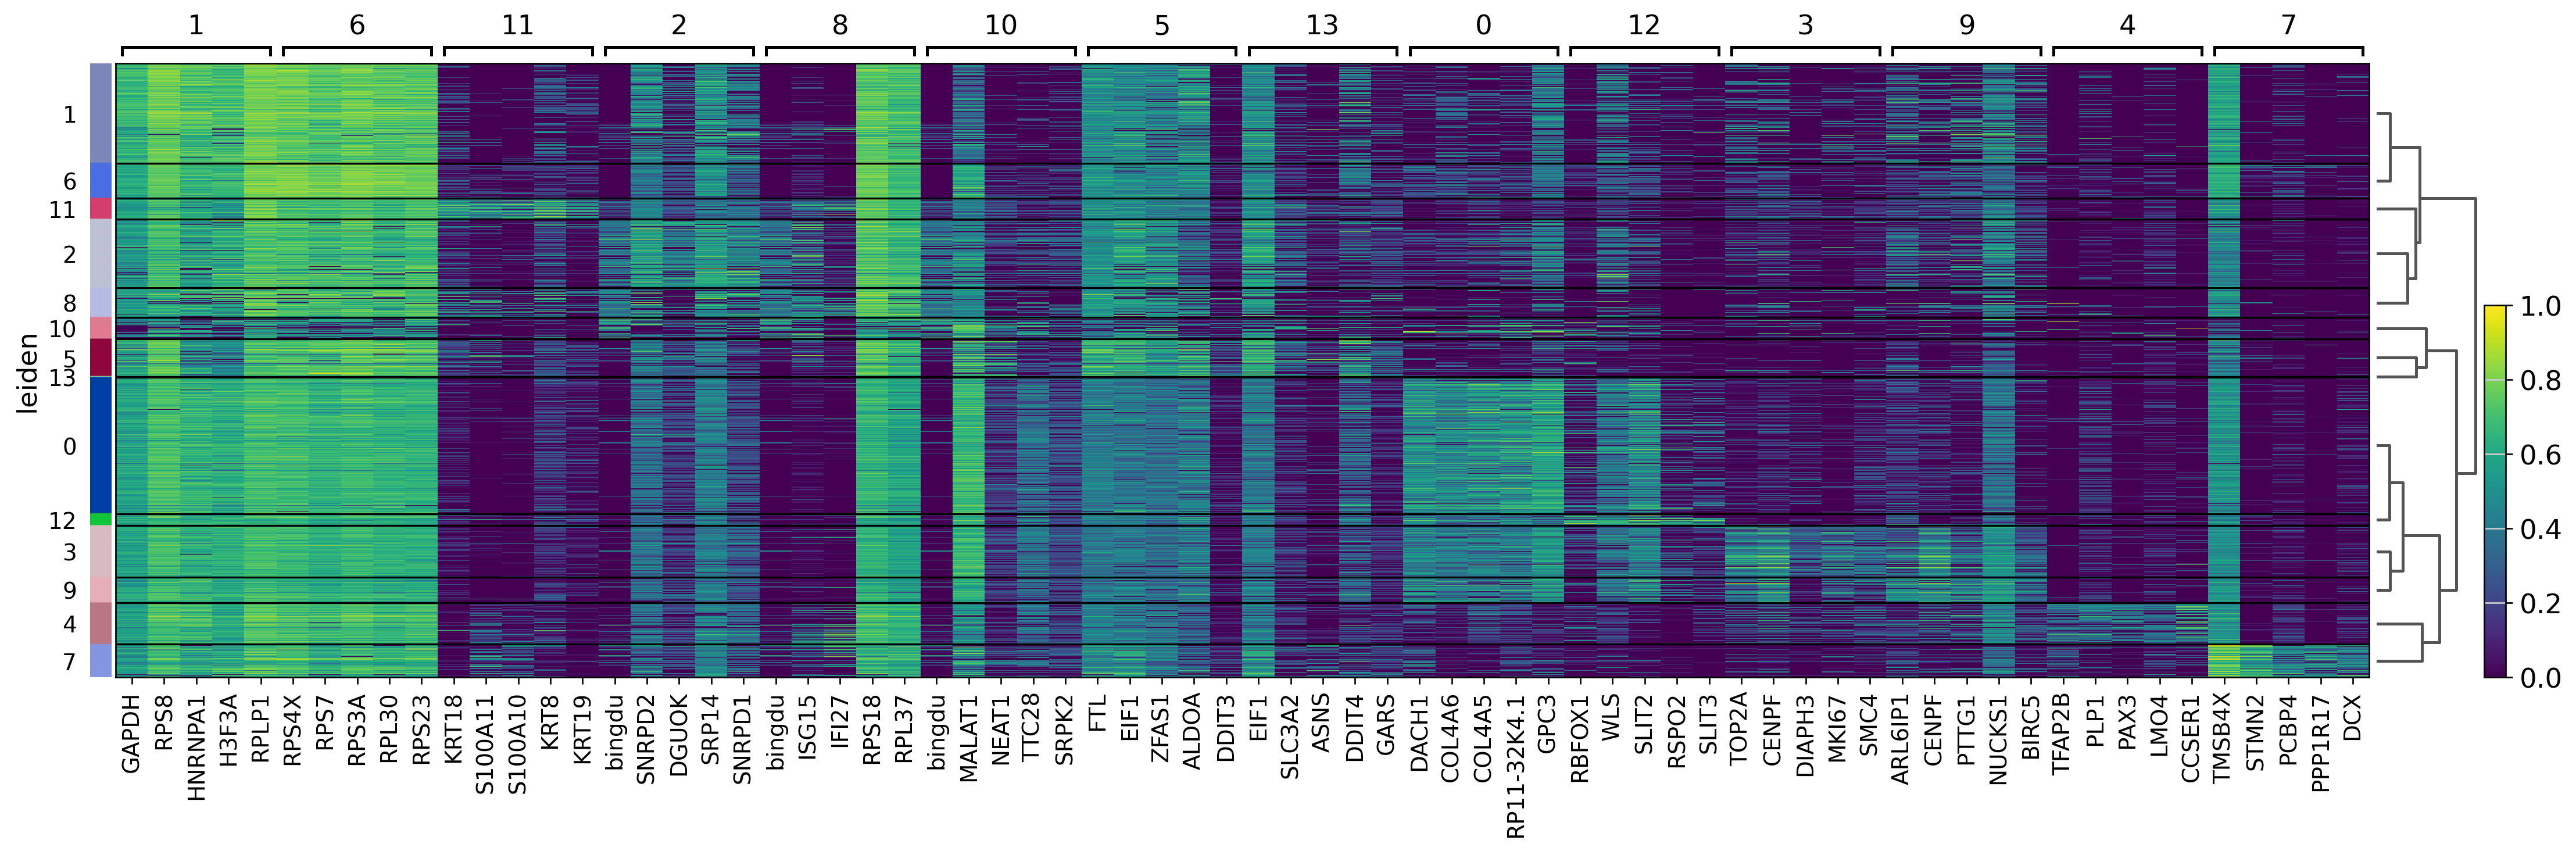

In [ ]:
adata.obs['leiden'] = adata.obs['leiden_res_0.6']
sc.tl.rank_genes_groups(adata, 'leiden', method='wilcoxon')
marker_genes = pd.DataFrame(adata.uns['rank_genes_groups']['names'])
print("Top 10 markers for all clusters (0-13):")
print(marker_genes.head(10))
sc.pl.rank_genes_groups_heatmap(adata, n_genes=5, standard_scale='var', show_gene_labels=True)

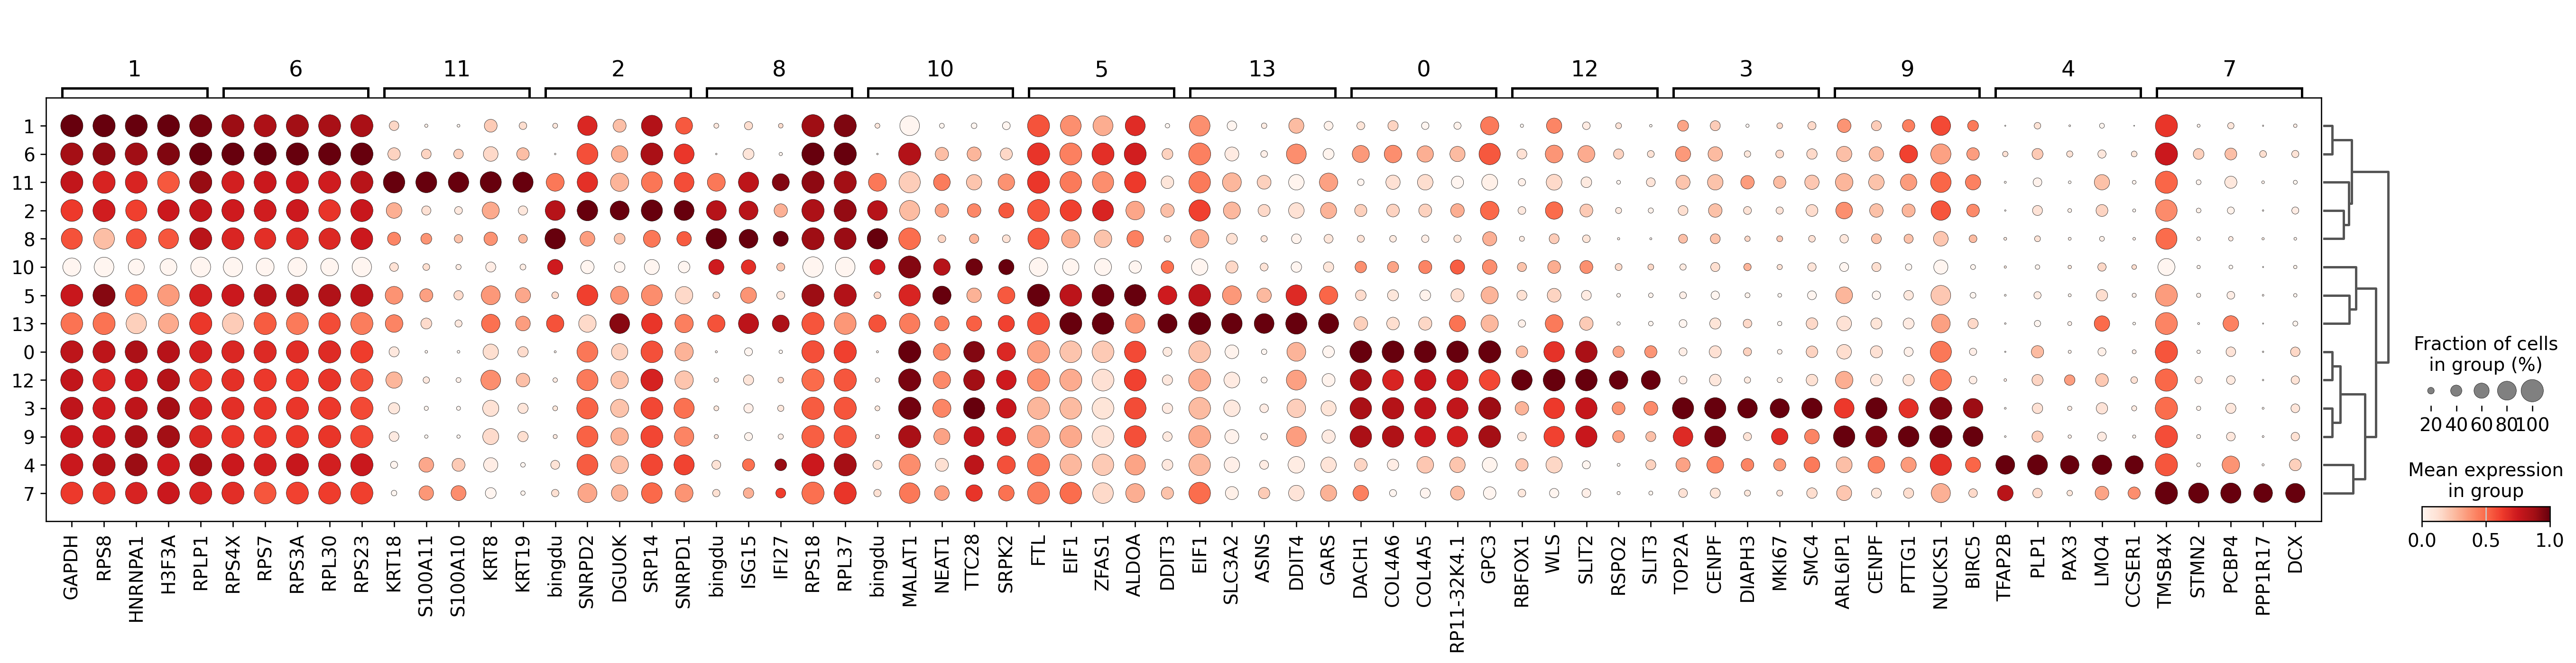

Top 10 markers for each cluster:
             0        1        2          3       4             5       6  \
0        DACH1    GAPDH   bingdu      TOP2A  TFAP2B           FTL   RPS4X   
1       COL4A6     RPS8   SNRPD2      CENPF    PLP1          EIF1    RPS7   
2       COL4A5  HNRNPA1    DGUOK     DIAPH3    PAX3         ZFAS1   RPS3A   
3  RP11-32K4.1    H3F3A    SRP14      MKI67    LMO4         ALDOA   RPL30   
4         GPC3    RPLP1   SNRPD1       SMC4  CCSER1         DDIT3   RPS23   
5        SLIT2     RPS6    ISG15     NUSAP1    NRP2        SQSTM1  RPS27A   
6        GPM6A    RPS24  TRMT112   HIST1H4C   ITGA4  EPB41L4A-AS1   RPL11   
7       CTNNA2     RPL7    SNRPB   MIS18BP1   ERBB3          VAT1   RPS12   
8        WNT5B    RPL41    SERF2  ARHGAP11B   ROBO1          ENO2   RPL10   
9       ADGRL3   EEF1A1    RPL38       ASPM  SEMA3C          NEU1   RPL24   

         7       8        9       10         11        12      13  
0   TMSB4X  bingdu  ARL6IP1   bingdu      KRT18    

In [ ]:
import scanpy as sc
import os
sc.settings.figdir = "/mnt/.../...../results/plots"
os.makedirs(sc.settings.figdir, exist_ok=True)
sc.settings.set_figure_params(dpi=120, dpi_save=300, frameon=False)

sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")

sc.pl.rank_genes_groups_dotplot(
    adata, 
    groupby="leiden", 
    standard_scale="var", 
    n_genes=5,
    save=".leiden_marker_dotplot.png"
)

marker_names = pd.DataFrame(adata.uns['rank_genes_groups']['names'])
print("Top 10 markers for each cluster:")
print(marker_names.head(10))